# Pipeline A (graded applicant): default prediction with the grade but without the interest rate

**The three settings of this project**

| Setting | Known when deciding | PD model | Rate model |
|---|---|---|---|
| Reference: already-priced loan | rate + grade | notebooks 02–05 | none (rate already set) |
| **Pipeline A: graded applicant** | **grade only** | **this notebook** | notebook 09 |
| Pipeline B: newcomer | neither | notebook 06 | notebook 07 |

**Pipeline A** is an applicant with a credit history whom the lender has already **graded (A–G)**, but whose **interest rate has not been decided yet**. The PD model may therefore use the grade, but **not** the rate (the rate is what notebook 09 will predict, so a PD that used it would leak the answer).

| Used | Removed |
|---|---|
| age, income, employment length, home ownership, loan intent, loan amount, loan-to-income, past default on file, credit-history length, **loan grade** | `loan_int_rate` |

**What this notebook does** (same 80% training set, same 5 folds, same exact cutoff search; the test set stays locked):
1. **Re-tune** every model family on these features (best settings can shift when features change).
2. **Validation scores for every model:** out-of-fold F1, precision, recall and ROC-AUC at each model's tuned cutoff, next to the same model's F1 when rate and grade are both known (notebooks 02–05).
3. **Probability of default:** calibrate every model's scores into PDs (as in notebook 04).
4. **Choose and save the PD model** (best tree-based model by Brier score) and its out-of-fold PDs, which become the input to the interest-rate model.

Trees and forests are trained without SMOTE (as in notebooks 03 and 05); logistic regression and the SVMs keep the with/without SMOTE comparison.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, train_test_split)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, DATA, REPORTS, APPLICANT_NUM_COLS, APPLICANT_CAT_COLS, load_train, make_cv,
                        make_pipeline, best_cutoff, fold_metrics, as_logit, crossfit_calibrate, ece)

X_train, y_train = load_train()
cv = make_cv()
NUM = APPLICANT_NUM_COLS
CAT = APPLICANT_CAT_COLS + ["loan_grade"]

def app_pipe(model, use_smote=False):
    # pipeline on this notebook's feature set
    return make_pipeline(model, use_smote, num_cols=NUM, cat_cols=CAT)

n_feat = app_pipe(LogisticRegression()).named_steps["prep"].fit(X_train).get_feature_names_out().size
print("numeric:", NUM)
print("categorical:", CAT)
print(f"{n_feat} features after one-hot encoding (26 with both rate and grade)")

numeric: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical: ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file', 'loan_grade']
25 features after one-hot encoding (26 with both rate and grade)


## Step 1: Re-tune every model family

Same folds; best = highest **mean validation F1** at the default cutoff:

| Model | Search |
|---|---|
| Logistic regression | C ∈ {0.01, 0.1, 1, 10, 100} (inverse regularisation strength), with and without SMOTE |
| Linear soft-margin SVM | C ∈ {0.01, 0.1, 1, 3, 10}, with and without SMOTE |
| RBF SVM | C ∈ {1, 10, 30, 100} × γ ∈ {0.01, 0.03, 0.1, 0.3} on an 8,000-row stratified subset, with and without SMOTE; the subset winner is scored on the full training set in Step 2 |
| Decision tree | max_depth × min_samples_leaf × criterion (30 combinations), no SMOTE |
| Random Forest (300 trees) | 15 random combinations of max_depth, min_samples_leaf, max_features, criterion; no SMOTE |

The RBF SVM and Random Forest searches are the slowest parts (several minutes each).

In [2]:
chosen = {}
start = time.time()

# Logistic regression and linear soft-margin SVM: sweep C
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for fam, make, grid in [("LogReg", lambda C: LogisticRegression(C=C, max_iter=2000), [0.01, 0.1, 1, 10, 100]),
                            ("Linear SVM", lambda C: LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000),
                             [0.01, 0.1, 1, 3, 10])]:
        for use_smote in (False, True):
            scores = {C: cross_validate(app_pipe(make(C), use_smote), X_train, y_train, cv=cv, scoring="f1",
                                        n_jobs=5)["test_score"].mean() for C in grid}
            C = max(scores, key=scores.get)
            chosen[f"{fam} {'+ SMOTE' if use_smote else '(no SMOTE)'}"] = {"C": C}
            print(f"{fam}, SMOTE={use_smote}: mean F1 by C", {k: round(v, 4) for k, v in scores.items()}, "-> C =", C)
print(f"[{time.time() - start:.0f}s]\n")

# RBF SVM: grid on a stratified 8,000-row subset of the training set
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)
cv_sub = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for use_smote in (False, True):
    t0 = time.time()
    gs = GridSearchCV(app_pipe(SVC(kernel="rbf"), use_smote),
                      {"model__C": [1, 10, 30, 100], "model__gamma": [0.01, 0.03, 0.1, 0.3]},
                      cv=cv_sub, scoring="f1", n_jobs=-1).fit(X_sub, y_sub)
    p = {"C": gs.best_params_["model__C"], "gamma": gs.best_params_["model__gamma"]}
    chosen[f"SVM RBF {'+ SMOTE' if use_smote else '(no SMOTE)'}"] = p
    print(f"RBF SVM, SMOTE={use_smote}: best on subset {p}, mean F1 {gs.best_score_:.4f}  [{time.time() - t0:.0f}s]")

# Decision tree: grid (no SMOTE)
gs = GridSearchCV(app_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                  {"model__max_depth": [6, 8, 10, 12, 15], "model__min_samples_leaf": [1, 5, 20],
                   "model__criterion": ["gini", "entropy"]}, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
chosen["Tree"] = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
print(f"\nDecision tree: best {chosen['Tree']}, mean F1 {gs.best_score_:.4f}")

# Random Forest: randomized search (no SMOTE)
t0 = time.time()
rs = RandomizedSearchCV(app_pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
                        {"model__max_depth": [None, 12, 20, 30], "model__min_samples_leaf": [1, 2, 5],
                         "model__max_features": ["sqrt", 0.3, 0.5, None], "model__criterion": ["gini", "entropy"]},
                        n_iter=15, cv=cv, scoring="f1", n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
chosen["Random Forest"] = {k.replace("model__", ""): v for k, v in rs.best_params_.items()}
print(f"Random Forest: best {chosen['Random Forest']}, mean F1 {rs.best_score_:.4f}  [{time.time() - t0:.0f}s]")
print(f"\nStep 1 total: {time.time() - start:.0f}s")

LogReg, SMOTE=False: mean F1 by C {0.01: np.float64(0.6011), 0.1: np.float64(0.6422), 1: np.float64(0.6472), 10: np.float64(0.6471), 100: np.float64(0.6473)} -> C = 100


LogReg, SMOTE=True: mean F1 by C {0.01: np.float64(0.6349), 0.1: np.float64(0.6416), 1: np.float64(0.6429), 10: np.float64(0.6429), 100: np.float64(0.6427)} -> C = 1


Linear SVM, SMOTE=False: mean F1 by C {0.01: np.float64(0.6239), 0.1: np.float64(0.6429), 1: np.float64(0.6463), 3: np.float64(0.6458), 10: np.float64(0.6461)} -> C = 1


Linear SVM, SMOTE=True: mean F1 by C {0.01: np.float64(0.6524), 0.1: np.float64(0.6551), 1: np.float64(0.6546), 3: np.float64(0.6552), 10: np.float64(0.6546)} -> C = 3
[74s]



RBF SVM, SMOTE=False: best on subset {'C': 100, 'gamma': 0.03}, mean F1 0.7661  [106s]


RBF SVM, SMOTE=True: best on subset {'C': 30, 'gamma': 0.03}, mean F1 0.7325  [236s]



Decision tree: best {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 5}, mean F1 0.8135


Random Forest: best {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30, 'criterion': 'gini'}, mean F1 0.8266  [2199s]

Step 1 total: 2636s


## Step 2: Validation scores of every model

For each model with its Step 1 settings: **out-of-fold scores** on the full training set (same 5 folds), then the **exact cutoff search** (every distinct score), and the mean over the 5 rounds of accuracy, precision, recall, F1 and ROC-AUC. The column *F1 with rate + grade* is the same model family's F1 when both are known (reference setting, notebooks 02–05), so the difference is the cost of not knowing them.

Out-of-fold scores are cached in `data/processed/oof_scores_graded.npz`.

In [3]:
def label(name, p):
    return f"{name} ({', '.join(f'{k}={v}' for k, v in p.items())})" if p else name

# F1 at the tuned cutoff in the reference setting (rate + grade known): notebooks 02-05
# (linear SVMs: F1 at the best PD cutoff from notebook 04, since notebook 02 did not cutoff-tune them)
REF_F1 = {"LogReg (no SMOTE)": 0.6762, "LogReg + SMOTE": 0.6738, "Linear SVM (no SMOTE)": 0.6825,
          "Linear SVM + SMOTE": 0.6796, "SVM RBF (no SMOTE)": 0.7845, "SVM RBF + SMOTE": 0.7728,
          "Tree": 0.8128, "Random Forest": 0.8298}
MODELS = {}   # name -> (pipeline, score method, reference F1)
for fam, smote in [("LogReg", False), ("LogReg", True)]:
    key = f"{fam} {'+ SMOTE' if smote else '(no SMOTE)'}"
    MODELS[label(key, chosen[key])] = (app_pipe(LogisticRegression(max_iter=2000, **chosen[key]), smote),
                                       "predict_proba", REF_F1[key])
for smote in (False, True):
    key = f"Linear SVM {'+ SMOTE' if smote else '(no SMOTE)'}"
    MODELS[label(key, chosen[key])] = (app_pipe(LinearSVC(loss="hinge", dual=True, max_iter=20000, **chosen[key]), smote),
                                       "decision_function", REF_F1[key])
for smote in (False, True):
    key = f"SVM RBF {'+ SMOTE' if smote else '(no SMOTE)'}"
    MODELS[label(key, chosen[key])] = (app_pipe(SVC(kernel="rbf", **chosen[key]), smote), "decision_function",
                                       REF_F1[key])
MODELS[label("Tree", chosen["Tree"])] = (app_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE, **chosen["Tree"])),
                                         "predict_proba", REF_F1["Tree"])
MODELS[label("Random Forest", chosen["Random Forest"])] = (
    app_pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **chosen["Random Forest"])),
    "predict_proba", REF_F1["Random Forest"])

CACHE = DATA / "oof_scores_graded.npz"
oof = dict(np.load(CACHE)) if CACHE.exists() else {}
rows = []
for name, (pipe, method, f1_ref) in MODELS.items():
    t0 = time.time()
    if name not in oof:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            s = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method, n_jobs=5)
        oof[name] = s[:, 1] if method == "predict_proba" else s
        np.savez(CACHE, **oof)
    s = oof[name]
    default = 0.5 if method == "predict_proba" else 0.0
    cut = best_cutoff(s, y_train)
    at_def, at_best = fold_metrics(s, y_train, default, X_train, cv), fold_metrics(s, y_train, cut, X_train, cv)
    rows.append({"model": name, "F1 @ default": at_def.loc["mean", "f1"], "best cutoff": cut,
                 "accuracy": at_best.loc["mean", "accuracy"], "precision": at_best.loc["mean", "precision"],
                 "recall": at_best.loc["mean", "recall"], "F1 @ best": at_best.loc["mean", "f1"],
                 "F1 sd": at_best.loc["sd", "f1"], "ROC-AUC": at_def.loc["mean", "roc_auc"],
                 "F1 with rate + grade": f1_ref})
    print(f"{name:<80} [{time.time() - t0:.0f}s]")

validation = pd.DataFrame(rows).set_index("model")
validation["F1 change"] = validation["F1 @ best"] - validation["F1 with rate + grade"]
print("\nValidation scores (5-fold CV, out-of-fold, each model at its own tuned cutoff):")
display(validation.sort_values("F1 @ best", ascending=False).round(4))

LogReg (no SMOTE) (C=100)                                                        [11s]


LogReg + SMOTE (C=1)                                                             [1s]


Linear SVM (no SMOTE) (C=1)                                                      [1s]


Linear SVM + SMOTE (C=3)                                                         [4s]


SVM RBF (no SMOTE) (C=100, gamma=0.03)                                           [44s]


SVM RBF + SMOTE (C=30, gamma=0.03)                                               [96s]


Tree (criterion=entropy, max_depth=12, min_samples_leaf=5)                       [0s]


Random Forest (min_samples_leaf=1, max_features=0.5, max_depth=30, criterion=gini) [17s]

Validation scores (5-fold CV, out-of-fold, each model at its own tuned cutoff):


,F1 @ default,best cutoff,accuracy,precision,recall,F1 @ best,F1 sd,ROC-AUC,F1 with rate + grade,F1 change
model,,,,,,,,,,
"Random Forest (min_samples_leaf=1, max_features=0.5, max_depth=30, criterion=gini)",0.8264,0.4700,0.9330,0.9510,0.7316,0.8269,0.0046,0.9336,0.8298,-0.0029
"Tree (criterion=entropy, max_depth=12, min_samples_leaf=5)",0.8129,0.6071,0.9296,0.9603,0.7072,0.8145,0.0041,0.9090,0.8128,0.0017
"SVM RBF (no SMOTE) (C=100, gamma=0.03)",0.7810,-0.1928,0.9163,0.9008,0.6942,0.7840,0.0092,0.9056,0.7845,-0.0005
"SVM RBF + SMOTE (C=30, gamma=0.03)",0.7556,0.3927,0.9104,0.8705,0.6937,0.7720,0.0107,0.9073,0.7728,-0.0008
Linear SVM (no SMOTE) (C=1),0.6452,-0.4337,0.8601,0.6767,0.6901,0.6833,0.0045,0.8654,0.6825,0.0008
Linear SVM + SMOTE (C=3),0.6548,0.4282,0.8587,0.6731,0.6885,0.6807,0.0076,0.8661,0.6796,0.0011
LogReg (no SMOTE) (C=100),0.6473,0.3547,0.8587,0.6760,0.6801,0.6779,0.0038,0.8685,0.6762,0.0017
LogReg + SMOTE (C=1),0.6429,0.6509,0.8559,0.6664,0.6841,0.6750,0.0057,0.8693,0.6738,0.0012


## Step 3: Probability of default for every model

Exactly as in notebook 04: every model's out-of-fold scores are turned into PDs with **raw** probabilities (where the model has them), **Platt scaling** and **isotonic regression**, each mapping fitted by **cross-fitting** (the mapping for fold *k* never sees fold *k*'s outcomes). For each model we keep the version with the lowest **Brier score**, and check that the mean PD matches the real default rate (0.219).

actual default rate = 0.2187. Best PD version per model (lowest Brier):


,PD method,mean PD,Brier,log loss,ECE,ROC-AUC
model,,,,,,
"Random Forest (min_samples_leaf=1, max_features=0.5, max_depth=30, criterion=gini)",isotonic,0.2186,0.0564,0.2038,0.0028,0.9325
"Tree (criterion=entropy, max_depth=12, min_samples_leaf=5)",isotonic,0.2193,0.0606,0.2262,0.0031,0.9080
"SVM RBF (no SMOTE) (C=100, gamma=0.03)",isotonic,0.2187,0.0692,0.2485,0.0020,0.9045
"SVM RBF + SMOTE (C=30, gamma=0.03)",isotonic,0.2186,0.0727,0.2579,0.0039,0.9056
Linear SVM (no SMOTE) (C=1),isotonic,0.2187,0.1014,0.3391,0.0030,0.8641
LogReg (no SMOTE) (C=100),isotonic,0.2186,0.1015,0.3383,0.0028,0.8664
LogReg + SMOTE (C=1),isotonic,0.2187,0.1028,0.3407,0.0026,0.8678
Linear SVM + SMOTE (C=3),isotonic,0.2187,0.1036,0.3438,0.0031,0.8645


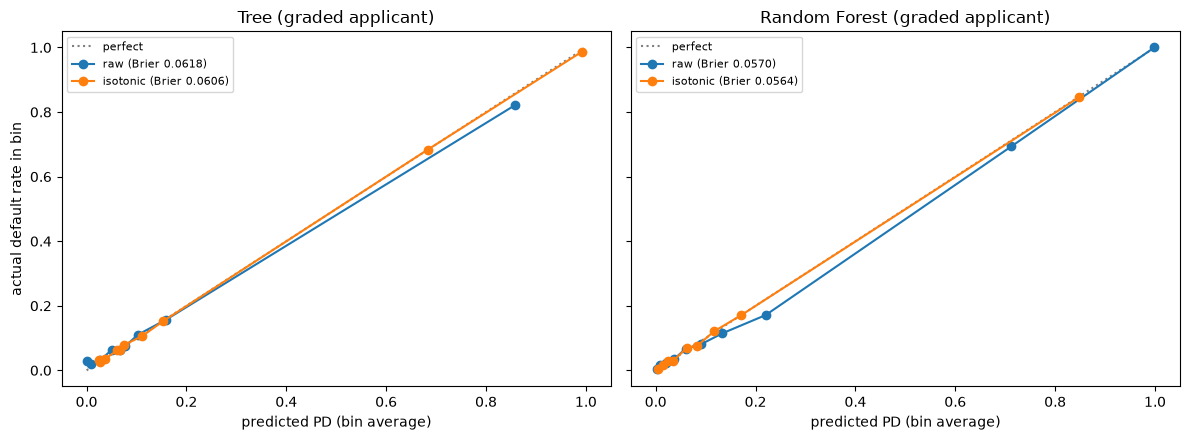

In [4]:
y = y_train.to_numpy()
pds, pd_rows = {}, []
for name, (_, method, _) in MODELS.items():
    s, is_prob = oof[name], method == "predict_proba"
    versions = {}
    if is_prob:
        versions["raw"] = np.clip(s, 1e-3, 1 - 1e-3)
    versions["Platt (sigmoid)"] = crossfit_calibrate(as_logit(s, is_prob), y_train, X_train, cv, "Platt (sigmoid)")
    versions["isotonic"] = crossfit_calibrate(s, y_train, X_train, cv, "isotonic")
    for how, p in versions.items():
        pds[(name, how)] = p
        pd_rows.append({"model": name, "PD method": how, "mean PD": p.mean(), "Brier": brier_score_loss(y, p),
                        "log loss": log_loss(y, p), "ECE": ece(p, y), "ROC-AUC": roc_auc_score(y, p)})
pd_all = pd.DataFrame(pd_rows).set_index(["model", "PD method"])
best_how = pd_all["Brier"].groupby(level="model").idxmin()
pd_best = pd_all.loc[best_how.values].reset_index(level="PD method").sort_values("Brier")
print(f"actual default rate = {y.mean():.4f}. Best PD version per model (lowest Brier):")
display(pd_best.round(4))

# Reliability diagrams for the two tree-based models
tree_models = [n for n in MODELS if n.startswith(("Tree", "Random Forest"))]
fig, axes = plt.subplots(1, len(tree_models), figsize=(12, 4.5), sharey=True)
for ax, name in zip(np.atleast_1d(axes), tree_models):
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect")
    for how in dict.fromkeys(["raw", pd_best.loc[name, "PD method"]]):
        frac, mean_pred = calibration_curve(y, pds[(name, how)], n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac, marker="o", label=f"{how} (Brier {pd_all.loc[(name, how), 'Brier']:.4f})")
    ax.set_title(name.split(" (")[0] + " (graded applicant)"); ax.set_xlabel("predicted PD (bin average)")
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("actual default rate in bin")
plt.tight_layout(); plt.show()

## Step 4: The PD model for this pipeline

Among the **tree-based models**, keep the one with the lowest Brier score. Its calibrated out-of-fold PD (one per training applicant) is saved for the interest-rate model, together with the F1-best PD cutoff (applicants at or above it are declined; below it they get a rate).

Then a first look at the link the rate model will learn: the **actual interest rate** each training applicant was charged, against their PD (applicants grouped into 20 equal-size PD bins).

PD model: Random Forest (min_samples_leaf=1, max_features=0.5, max_depth=30, criterion=gini)  [isotonic]
PD cutoff 0.367: F1 0.8269, precision 0.9510, recall 0.7316; approved share 0.832
saved data/processed/oof_pd_graded.csv, reports/graded_pd_choice.json, reports/graded_validation.csv, reports/graded_pd_summary.csv


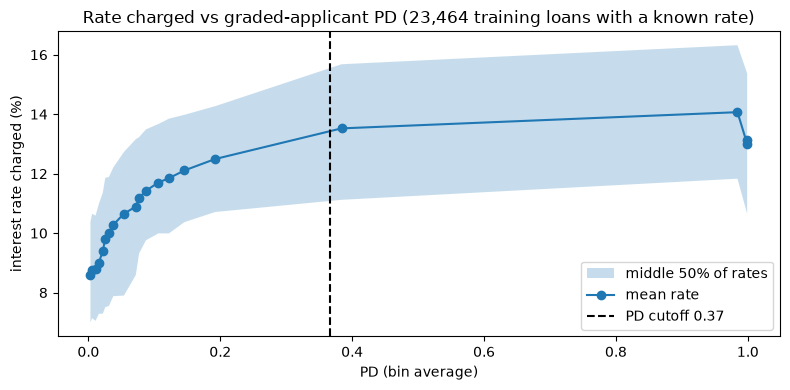

correlation between PD and rate: 0.388


In [5]:
pd_name = pd_best.loc[tree_models, "Brier"].idxmin()
pd_how = pd_best.loc[pd_name, "PD method"]
this_pd = pds[(pd_name, pd_how)]
pd_cut = best_cutoff(this_pd, y_train)
fm = fold_metrics(this_pd, y_train, pd_cut, X_train, cv)
print(f"PD model: {pd_name}  [{pd_how}]")
print(f"PD cutoff {pd_cut:.3f}: F1 {fm.loc['mean', 'f1']:.4f}, precision {fm.loc['mean', 'precision']:.4f}, "
      f"recall {fm.loc['mean', 'recall']:.4f}; approved share {np.mean(this_pd < pd_cut):.3f}")

out = pd.DataFrame({"graded_pd": this_pd, "loan_int_rate": X_train["loan_int_rate"].values, "loan_status": y})
out.to_csv(DATA / "oof_pd_graded.csv", index=False)
model_key = "Tree" if pd_name.startswith("Tree") else "Random Forest"
choice = {"pipeline": "A (graded applicant)", "model": model_key, "params": chosen[model_key], "calibration": pd_how,
          "pd_cutoff": pd_cut, "cv_f1_at_cutoff": float(fm.loc["mean", "f1"]),
          "cv_precision_at_cutoff": float(fm.loc["mean", "precision"]), "cv_recall_at_cutoff": float(fm.loc["mean", "recall"]),
          "brier": float(pd_best.loc[pd_name, "Brier"]), "features": {"numeric": NUM, "categorical": CAT},
          "n_estimators": 300 if model_key == "Random Forest" else None, "all_chosen_settings": chosen}
(REPORTS / "graded_pd_choice.json").write_text(json.dumps(choice, indent=2, default=str))
validation.round(4).to_csv(REPORTS / "graded_validation.csv")
pd_best.round(4).to_csv(REPORTS / "graded_pd_summary.csv")
print("saved data/processed/oof_pd_graded.csv, reports/graded_pd_choice.json, reports/graded_validation.csv, "
      "reports/graded_pd_summary.csv")

# Preview: interest rate vs this pipeline's PD (rows with a known rate)
known = out.dropna(subset=["loan_int_rate"]).copy()
known["PD bin"] = pd.qcut(known["graded_pd"].rank(method="first"), 20, labels=False)
binned = known.groupby("PD bin").agg(mean_PD=("graded_pd", "mean"), mean_rate=("loan_int_rate", "mean"),
                                     q25=("loan_int_rate", lambda s: s.quantile(0.25)),
                                     q75=("loan_int_rate", lambda s: s.quantile(0.75)))
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(binned["mean_PD"], binned["q25"], binned["q75"], alpha=0.25, label="middle 50% of rates")
ax.plot(binned["mean_PD"], binned["mean_rate"], marker="o", label="mean rate")
ax.axvline(pd_cut, color="black", linestyle="--", label=f"PD cutoff {pd_cut:.2f}")
ax.set_xlabel("PD (bin average)"); ax.set_ylabel("interest rate charged (%)")
ax.set_title(f"Rate charged vs graded-applicant PD ({len(known):,} training loans with a known rate)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"correlation between PD and rate: {known[['graded_pd', 'loan_int_rate']].corr().iloc[0, 1]:.3f}")

## Step 5: The three settings side by side (validation, training set)

The chosen PD model of each setting, at its own tuned cutoff (5-fold CV, out-of-fold).

In [6]:
newcomer = json.loads((REPORTS / "applicant_pd_choice.json").read_text())
three = pd.DataFrame([
    {"setting": "Reference: rate + grade known (nb 05)", "PD model": "Random Forest", "F1": 0.8298, "Brier": 0.0556},
    {"setting": "Pipeline A: grade known (this notebook)", "PD model": model_key,
     "F1": choice["cv_f1_at_cutoff"], "Brier": choice["brier"]},
    {"setting": "Pipeline B: newcomer (nb 06)", "PD model": newcomer["model"],
     "F1": newcomer["cv_f1_at_cutoff"], "Brier": newcomer["brier"]},
]).set_index("setting")
display(three.round(4))

,PD model,F1,Brier
setting,,,
Reference: rate + grade known (nb 05),Random Forest,0.8298,0.0556
Pipeline A: grade known (this notebook),Random Forest,0.8269,0.0564
Pipeline B: newcomer (nb 06),Random Forest,0.6908,0.0879
